# Рекомендации комиксов и графических романов
Коротков Станислав Игоревич

Использую [Goodreads, Comics & Graphic](https://cseweb.ucsd.edu/~jmcauley/datasets/goodreads.html). Рекомендую товары, на которые пользователь еще не оставил отзыв, положительными считаю оценки 4 и 5.

Для запуска нужно установить `requirements.txt` и выполнить ячейки по порядку. Данные скачиваются автоматически. `RETRAIN = True` запускает обучение заново, иначе загружаются результаты из `results/`.

In [1]:
import json
import random
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display
from data import prepare
from experiment import run, settings

random.seed(17)
np.random.seed(17)
RETRAIN = False
plt.rcParams.update({'figure.figsize': (10, 4), 'axes.grid': True, 'grid.alpha': .2})
pd.set_option('display.max_colwidth', 100)

## Подготовка отзывов
В данных есть `user_id`, `book_id`, `rating` и `date_updated`. Нулевая оценка означает отсутствие оценки, такие строки убираю. За время взаимодействия беру обновление отзыва, поскольку итоговая оценка могла появиться позже добавления книги. Если пара повторяется, оставляю первую запись.

Делю отзывы по времени на 80/10/10, затем по train оставляю 3 500 популярных книг и до 12 000 активных читателей с минимум четырьмя отзывами на них. Равные частоты разрешаю сортировкой ID. Выборка получается меньше, но остается достаточно большой для сравнения.

Источник: Mengting Wan, Julian McAuley, Item Recommendation on Monotonic Behavior Chains, 2018. Использую подробные отзывы, а не все записи с книжных полок.

In [2]:
raw, selected, train, validation, test, metadata, info = prepare()
shape = (info['users'], info['items'])
display(pd.Series({key: info[key] for key in ['raw_rows', 'invalid_rows', 'duplicate_pairs', 'clean_rows', 'rows', 'users', 'items', 'sparsity']}, name='Значение').to_frame())
display(pd.Series(info['missing'], name='Пропуски').to_frame())

,Значение
raw_rows,542338.000000
invalid_rows,12806.000000
duplicate_pairs,0.000000
clean_rows,529532.000000
rows,206097.000000
users,11291.000000
items,3500.000000
sparsity,0.994785


,Пропуски
user_id,0
item_id,0
rating,0
timestamp,0


## Что получилось после отбора
Сравниваю оценки до и после отбора, смотрю распределение числа отзывов и заполненность данных о книгах.

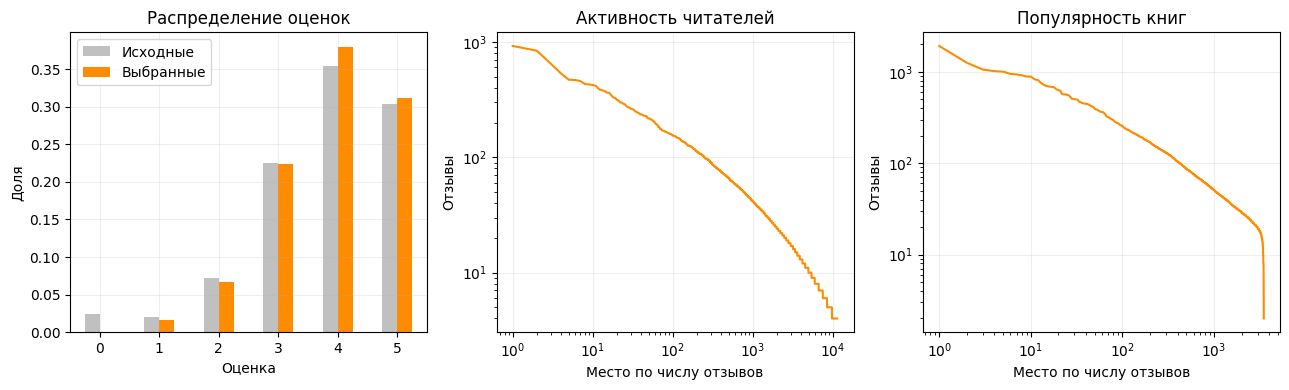

In [3]:
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
pd.concat([raw.rating.value_counts(normalize=True).rename('Исходные'), selected.rating.value_counts(normalize=True).rename('Выбранные')], axis=1).sort_index().plot.bar(ax=axes[0], rot=0, color=['silver', 'darkorange'])
axes[0].set(title='Распределение оценок', xlabel='Оценка', ylabel='Доля')
for ax, column, title in [(axes[1], 'user', 'Активность читателей'), (axes[2], 'item', 'Популярность книг')]:
    counts = selected.groupby(column).size().sort_values(ascending=False).to_numpy()
    ax.plot(np.arange(1, len(counts)+1), counts, color='darkorange')
    ax.set(xscale='log', yscale='log', title=title, xlabel='Место по числу отзывов', ylabel='Отзывы')
plt.tight_layout()
plt.show()

,Заполненность
title,1.000000
pages,0.912857
year,0.914000
language,0.856571


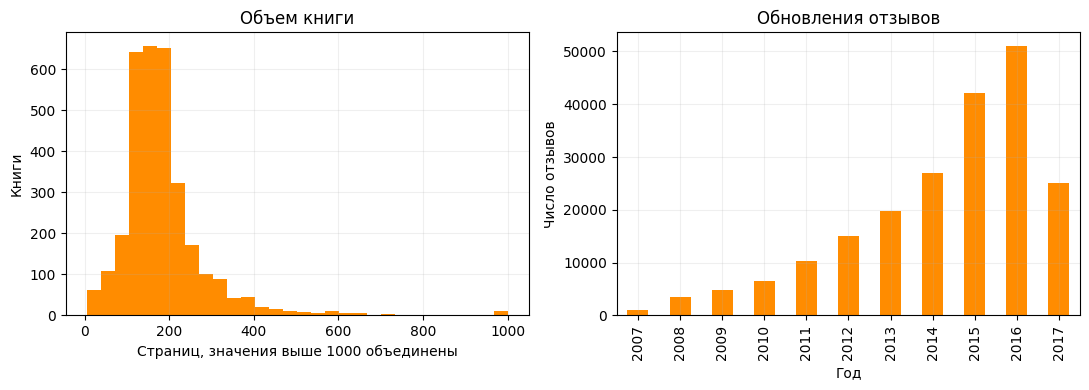

,title,pages,year
item_id,,,
10001434,Congress of the Animals,104.0,2011.0
1000846,"Rex Libris, Volume I: I, Librarian (Rex Libris, #1-5)",176.0,2007.0
100094,Midnight Nation,304.0,2004.0
10023145,"Scarlet, Book 1 (Scarlet, #1)",176.0,2011.0
1003761,"Beauty Pop, Vol. 1 (Beauty Pop, #1)",208.0,2006.0


In [4]:
display(metadata.replace('', np.nan).notna().mean().rename('Заполненность').to_frame())
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
metadata.pages.dropna().clip(upper=1000).hist(bins=30, ax=axes[0], color='darkorange')
axes[0].set(title='Объем книги', xlabel='Страниц, значения выше 1000 объединены', ylabel='Книги')
pd.to_datetime(selected.timestamp, unit='s', utc=True).dt.year.value_counts().sort_index().plot.bar(ax=axes[1], color='darkorange')
axes[1].set(title='Обновления отзывов', xlabel='Год', ylabel='Число отзывов')
plt.tight_layout()
plt.show()
display(metadata[['title', 'pages', 'year']].head())

## Как сравниваю модели
Одинаковые временные метки не разделяю. Каталог и пользователи фиксируются по train, в каждом периоде беру общий набор пользователей с доступными положительными отзывами. Новые пользователи и объекты не участвуют в сравнении.

Ранжирую весь каталог и убираю все ранее оцененные объекты, включая низкие оценки. История внутри периода не обновляется, при равных предсказаниях сортирую ID.

Основная метрика NDCG@10 учитывает порядок списка, Recall@10 показывает долю найденных положительных объектов. Обе считаю в среднем по пользователям. После подбора обучаю модели на train + validation и оцениваю на test.

In [5]:
print('Границы периодов:', pd.to_datetime(info['cutoffs'], unit='s', utc=True).strftime('%Y-%m-%d').tolist())
display(pd.DataFrame([{'period': name, 'rows': len(frame), 'users': frame.user.nunique(), 'items': frame.item.nunique()}
                      for name, frame in [('train', train), ('validation', validation), ('test', test)]]))
display(pd.DataFrame(info['excluded']))

Границы периодов: ['2017-01-25', '2017-06-23']


,period,rows,users,items
0,train,185179,11291,3500
1,validation,12456,3398,2542
2,test,8462,2524,2334


,period,before_filter,retained,new_users,new_items
0,validation,52953,12456,4132,7143
1,test,52954,8462,4491,8945


$$NDCG_u@10=\frac{\sum_{j=1}^{10}\mathbb{1}[i_j\in R_u]/\log_2(j+1)}{\sum_{j=1}^{\min(10,|R_u|)}1/\log_2(j+1)},\qquad Recall_u@10=\frac{|L_u^{10}\cap R_u|}{|R_u|}.$$

## Реализации
$X$ содержит единицы для оценок 4 и 5.

UserCF ищет похожих читателей по косинусному сходству:
$$s_{uv}=\frac{X_uX_v^T}{\|X_u\|\|X_v\|},\qquad \hat y_{ui}=\frac{\sum_{v\in N_k(u)}s_{uv}X_{vi}}{\sum_{v\in N_k(u)}s_{uv}}.$$
Самого пользователя из соседей исключаю.

В iALS минимизирую
$$\sum_{u,i}c_{ui}(p_{ui}-a_u^Tb_i)^2+\lambda(\|A\|_F^2+\|B\|_F^2).$$
$p_{ui}=\mathbb{1}[r_{ui}\ge4]$, confidence равен 11 для известных пар и 1 для остальных. Решаю системы по очереди для пользователей и книг.

GradedALS меняет только предпочтение:
$$t_{ui}=\max(r_{ui}-2,0)/3.$$
Тройки дают слабый положительный сигнал, четверки и пятерки более сильный. Проверяю, поможет ли такая градация при том же критерии релевантности 4 и 5.

Для EASE решаю задачу
$$\min_W\|X-XW\|_F^2+\lambda\|W\|_F^2,\quad W_{ii}=0.$$
Вычисляю $P=(X^TX+\lambda I)^{-1}$ и $W_{ij}=-P_{ij}/P_{jj}$ при $i\ne j$, затем использую $XW$.

FM добавляет к ID читателя и книги дополнительные признаки:
$$\hat y(x)=w_0+\sum_jw_jx_j+\sum_{j<k}\langle v_j,v_k\rangle x_jx_k.$$
Для читателя беру логарифм числа прошлых отзывов, среднюю оценку / 5 и долю положительных оценок. Для книги использую прошлую популярность, $\log(1+pages)/8$ и $(year-1900)/120$. Число страниц и год считаю фиксированными характеристиками издания, известными к моменту отзыва. Пропуски заменяю нулем после преобразования.

Популярность и признаки читателя считаются строго по предыдущим отзывам. На каждый отзыв добавляю один случайный неизвестный пользователю товар с меткой 0. Оптимизирую BCE через AdamW с шагом 0,003 и batch 2048.

## Подбор
Использую seed 17. Сетки приведены ниже, выбор идет по NDCG@10 на validation. Для ALS беру 10 итераций, для FM до 15 эпох с остановкой после трех эпох без улучшения.

После выбора повторяю сравнение двух ALS с одинаковыми параметрами и FM без дополнительных признаков. Эти настройки фиксируются до оценки test. Для FM на train + validation использую лучшую эпоху с validation.

In [6]:
display(pd.DataFrame([{'model': name, 'parameters': parameters} for name, parameters in settings()]))
path = Path('results/report.json')
report = run() if RETRAIN or not path.exists() else json.loads(path.read_text())
print('Пользователи validation:', report['validation_users'], 'test:', report['test_users'])
search = pd.DataFrame([{k: v for k, v in row.items() if k != 'history'} for row in report['search']])
display(search.sort_values(['model', 'NDCG@10'], ascending=[True, False]))

,model,parameters
0,UserCF,{'neighbors': 20}
1,UserCF,{'neighbors': 60}
2,UserCF,{'neighbors': 120}
3,EASE,{'regularization': 50}
4,EASE,{'regularization': 250}
5,EASE,{'regularization': 1000}
6,iALS,"{'dimensions': 24, 'regularization': 0.5}"
7,iALS,"{'dimensions': 24, 'regularization': 5.0}"
8,iALS,"{'dimensions': 48, 'regularization': 0.5}"
9,iALS,"{'dimensions': 48, 'regularization': 5.0}"


Пользователи validation: 2827 test: 2067


,model,parameters,seconds,NDCG@10,Recall@10,best_epoch
4,EASE,{'regularization': 250},2.539279,0.094273,0.133387,NaN
3,EASE,{'regularization': 50},2.609468,0.093578,0.131966,NaN
5,EASE,{'regularization': 1000},2.659495,0.092542,0.133292,NaN
16,FM,"{'factors': 32, 'reg': 1e-05}",5.268264,0.065509,0.107331,1.0
17,FM,"{'factors': 32, 'reg': 0.0001}",5.096184,0.065509,0.107331,1.0
14,FM,"{'factors': 16, 'reg': 1e-05}",7.273945,0.063930,0.106354,1.0
15,FM,"{'factors': 16, 'reg': 0.0001}",4.453811,0.063930,0.106354,1.0
13,GradedALS,"{'dimensions': 48, 'regularization': 5.0}",3.652041,0.079255,0.114779,NaN
12,GradedALS,"{'dimensions': 48, 'regularization': 0.5}",3.624792,0.079122,0.116403,NaN
10,GradedALS,"{'dimensions': 24, 'regularization': 0.5}",2.181582,0.074082,0.113438,NaN


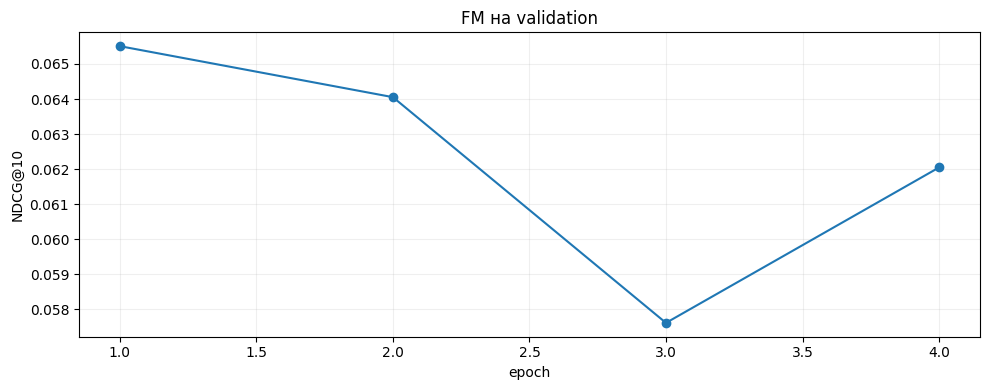

In [7]:
curve = max([row for row in report['search'] if row['model'] == 'FM'], key=lambda row: row['NDCG@10'])
pd.DataFrame(curve['history']).plot(x='epoch', y='ndcg', marker='o', legend=False, title='FM на validation')
plt.ylabel('NDCG@10')
plt.tight_layout()
plt.show()

## Итоговое сравнение
В таблице метрики на test, параметры и время обучения в секундах. Для FM время первого запуска включает подготовку признаков.

,parameters,seconds,NDCG@10,Recall@10
model,,,,
EASE,{'regularization': 250},3.045269,0.091380,0.141906
UserCF,{'neighbors': 120},2.779639,0.078288,0.124627
GradedALS,"{'dimensions': 48, 'regularization': 5.0}",3.700948,0.071028,0.113073
iALS,"{'dimensions': 48, 'regularization': 5.0}",3.707325,0.064878,0.106542
FM,"{'factors': 32, 'reg': 1e-05, 'epochs': 1}",2.394068,0.047550,0.085959


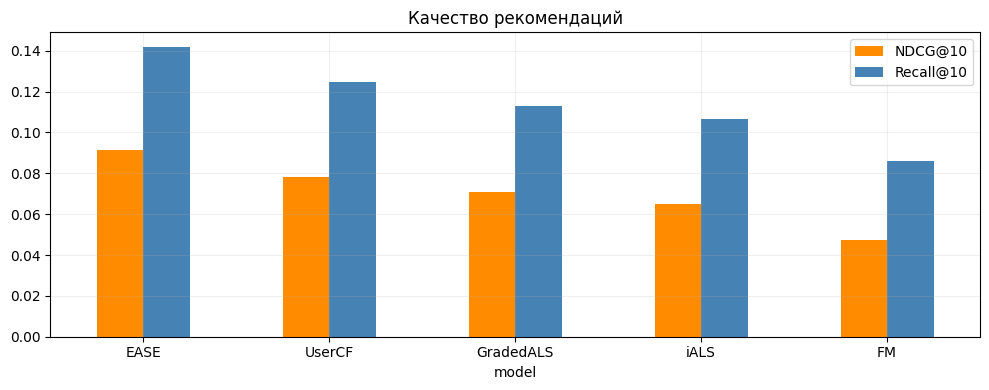

,parameters,seconds,NDCG@10,Recall@10
model,,,,
iALS,"{'dimensions': 48, 'regularization': 5.0}",3.707325,0.064878,0.106542
GradedALS,"{'dimensions': 48, 'regularization': 5.0}",3.700948,0.071028,0.113073
GradedALS_matched,"{'dimensions': 48, 'regularization': 5.0}",3.700948,0.071028,0.113073
FM,"{'factors': 32, 'reg': 1e-05, 'epochs': 1}",2.394068,0.047550,0.085959
FM_ID,"{'factors': 32, 'reg': 1e-05, 'epochs': 1, 'metadata': False}",0.647478,0.054527,0.083913


In [8]:
final = pd.DataFrame(report['final']).set_index('model')
main = final.loc[['UserCF', 'iALS', 'GradedALS', 'EASE', 'FM']].sort_values('NDCG@10', ascending=False)
display(main)
main[['NDCG@10', 'Recall@10']].plot.bar(rot=0, color=['darkorange', 'steelblue'], title='Качество рекомендаций')
plt.tight_layout()
plt.show()
display(final.loc[['iALS', 'GradedALS', 'GradedALS_matched', 'FM', 'FM_ID']])

In [9]:
example = report['example']
print('Пример рекомендаций EASE для пользователя', example['user'])
display(metadata.iloc[example['items']][['title']].assign(rank=np.arange(1, 11)))

Пример рекомендаций EASE для пользователя 7


,title,rank
item_id,,
17210470,"Boxers (Boxers & Saints, #1)",1
9517,"Persepolis 2: The Story of a Return (Persepolis, #2)",2
118944,American Born Chinese,3
26247042,"Orange: The Complete Collection, Vol. 2",4
22504701,Roller Girl,5
9615347,Anya's Ghost,6
10912036,"Pretty Guardian Sailor Moon, Vol. 2 (Pretty Soldier Sailor Moon Renewal Edition, #2)",7
17571564,"Hyperbole and a Half: Unfortunate Situations, Flawed Coping Mechanisms, Mayhem, and Other Things...",8
18465566,This One Summer,9


## Выводы
На этой выборке EASE оказался лучшим по обеим метрикам: NDCG@10 0.09138 и Recall@10 0.14191 при регуляризации 250. Второе место занял UserCF со 120 соседями.

Градуированный таргет улучшил iALS: при одинаковых настройках NDCG@10 вырос с 0.06488 до 0.07103. У FM дополнительные признаки снизили NDCG@10 с 0.05453 до 0.04755, хотя Recall@10 немного вырос. В этой настройке они не помогли порядку рекомендаций.

Оценка проведена на 2067 читателях, у которых были подходящие отзывы в test. Выбраны популярные книги и активные читатели, поэтому холодный старт остается за рамками работы. Год и объем книги считаю постоянными свойствами издания, история исправлений метаданных неизвестна. По одному разбиению нельзя судить об устойчивости небольших различий.